# 13c · Cap EEG technical validation


In [1]:
import json
import sys
from pathlib import Path

sys.dont_write_bytecode = True
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyxdf
from IPython.display import display
from mne.preprocessing import ICA
from mne_icalabel import label_components
from scipy import signal
from scipy.interpolate import interp1d

PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / 'helpers/project_config.py').is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from helpers.project_config import load_project_config

CONFIG = load_project_config(PROJECT_ROOT / 'config.json')
XDF_ROOT = CONFIG.path('paths', 'preprocessed_data_root') / 'XDF'
CAP_STREAM_NAME = CONFIG.value('modalities', 'cap_eeg_stream_name')
CACHE_DIR = PROJECT_ROOT / '.cache' / '13c_cap_eeg'

# Task presentation markers from 13a; keypress markers are not task onsets.
EVENT_ID = {name: i for i, name in enumerate(
    ['easy_correct', 'easy_wrong', 'hard_correct', 'hard_wrong'], start=1
)}
ICA_L_FREQ, ICA_H_FREQ = 1.0, 100.0
L_FREQ, H_FREQ, NOTCH_FREQ = 1.0, 45.0, 50.0
TMIN, TMAX = -1.0, 5.0
SFREQ, TFR_SFREQ = 250.0, 200.0  # Native SMARTING rate for ICA; downsample after 45 Hz filtering.
FILTER_PAD = 3.0
EXTRACTION_TIMES = np.arange(
    round((TMIN - FILTER_PAD) * SFREQ), round((TMAX + FILTER_PAD) * SFREQ) + 1
) / SFREQ
ICA_REJECT = {'eeg': 1e-3}  # Gross 1 mV peak-to-peak segments do not train ICA.
REJECT = {'eeg': 200e-6}
FLAT = {'eeg': 0.5e-6}
IC_PROBABILITY = 0.80
WINDOW_S, STEP_S = 0.75, 0.025  # Hann equivalent-noise bandwidth: 2 Hz.
EPOCH_TMIN, EPOCH_TMAX = TMIN - WINDOW_S / 2, TMAX + WINDOW_S / 2

# Recording stem -> channel names or reviewed ICA indices; empty uses automatic decisions.
BAD_CHANNELS = {}
ICA_EXCLUDE = {}
KEEP_CHANNELS = ['P7', 'P3', 'P4', 'P8', 'O1', 'O2', 'M1', 'M2']

In [2]:
def read_recording(path):
    headers = pyxdf.resolve_streams(str(path))
    marker_name = 'Markers' if any(s['name'] == 'Markers' for s in headers) else 'Triggers'
    selected = [s for s in headers if s['name'] in (CAP_STREAM_NAME, marker_name)]
    if sorted(s['name'] for s in selected) != sorted([CAP_STREAM_NAME, marker_name]):
        raise ValueError(f'{path.name}: expected one cap EEG and one marker stream')
    streams, _ = pyxdf.load_xdf(
        str(path), select_streams=[s['stream_id'] for s in selected],
        synchronize_clocks=True, dejitter_timestamps=True, verbose=False,
    )
    streams = {s['info']['name'][0]: s for s in streams}
    eeg, markers = streams[CAP_STREAM_NAME], streams[marker_name]
    channels = eeg['info']['desc'][0]['channels'][0]['channel']
    picks = [i for i, ch in enumerate(channels)
             if ch['label'][0] not in BAD_CHANNELS.get(path.stem, [])]
    names = [channels[i]['label'][0] for i in picks]
    # These SMARTING cap streams store EEG in microvolts (manufacturer specification).
    values = np.asarray(eeg['time_series'], dtype=float)[:, picks] * 1e-6
    times = np.asarray(eeg['time_stamps'], dtype=float)
    if len(names) < 3:
        raise ValueError(f'{path.name}: fewer than three usable EEG channels')
    if not np.isfinite(times).all() or np.any(np.diff(times) <= 0):
        raise ValueError(f'{path.name}: cap EEG timestamps must be finite and increasing')
    trials = pd.DataFrame({
        'lsl_time_s': np.asarray(markers['time_stamps'], dtype=float),
        'marker': np.asarray(markers['time_series']).reshape(-1),
    })
    trials = trials.loc[trials['marker'].isin(EVENT_ID)].sort_values('lsl_time_s')
    return values, times, names, trials.reset_index(drop=True)


def filter_and_epoch(values, times, marker_times):
    native_sfreq = 1.0 / np.median(np.diff(times))
    bandpass = signal.butter(
        4, [ICA_L_FREQ, ICA_H_FREQ], btype='bandpass', fs=native_sfreq, output='sos'
    )
    notch_b, notch_a = signal.iirnotch(NOTCH_FREQ, Q=30, fs=native_sfreq)
    finite = np.isfinite(values).all(axis=1)
    breaks = np.flatnonzero(
        (np.diff(times) > 1.5 / native_sfreq) | ~finite[:-1] | ~finite[1:]
    ) + 1
    bounds = np.r_[0, breaks, len(times)]
    epochs, kept = [], []
    for start, stop in zip(bounds[:-1], bounds[1:]):
        if not finite[start] or times[stop - 1] - times[start] < EXTRACTION_TIMES[-1] - EXTRACTION_TIMES[0]:
            continue
        inside = np.flatnonzero(
            (marker_times + EXTRACTION_TIMES[0] >= times[start])
            & (marker_times + EXTRACTION_TIMES[-1] <= times[stop - 1])
        )
        if not len(inside):
            continue
        filtered = signal.sosfiltfilt(bandpass, values[start:stop].T, axis=-1)
        filtered = signal.filtfilt(notch_b, notch_a, filtered, axis=-1)
        interpolate = interp1d(times[start:stop], filtered, axis=-1, assume_sorted=True)
        for trial in inside:
            epochs.append(interpolate(marker_times[trial] + EXTRACTION_TIMES))
            kept.append(trial)
    return np.asarray(epochs), np.asarray(kept, dtype=int)


In [3]:
def clean_epochs(data, names, trials, recording):
    info = mne.create_info(names, SFREQ, ch_types='eeg')
    # Record the filters already applied with SciPy.
    with info._unlock():
        info['highpass'], info['lowpass'] = ICA_L_FREQ, ICA_H_FREQ
    events = np.column_stack((
        np.arange(len(data)) * data.shape[-1],
        np.zeros(len(data), dtype=int),
        trials['marker'].map(EVENT_ID).to_numpy(),
    )).astype(int)
    epochs = mne.EpochsArray(
        data, info, events=events, event_id=EVENT_ID, tmin=TMIN - FILTER_PAD,
        reject_tmin=TMIN, reject_tmax=TMAX, baseline=None,
        on_missing='ignore', verbose=False,
    )
    epochs.set_montage('standard_1005', match_case=False)
    # Reject flat/gross segments before reference spreading and ICA fitting.
    epochs.drop_bad(reject=ICA_REJECT, flat=FLAT, verbose=False)
    epochs.set_eeg_reference('average', projection=False, verbose=False)
    epochs.drop_bad(reject=ICA_REJECT, flat=FLAT, verbose=False)
    fit_epochs = epochs.copy().crop(TMIN, TMAX)
    if len(fit_epochs) < 2:
        return fit_epochs, fit_epochs[:0], None, pd.DataFrame()
    ica = ICA(method='infomax', fit_params={'extended': True},
              random_state=97, max_iter='auto')
    ica.fit(fit_epochs, verbose=False)
    prediction = label_components(fit_epochs, ica, method='iclabel')
    labels = np.asarray(prediction['labels'])
    probability = np.asarray(prediction['y_pred_proba'])
    automatic = np.flatnonzero(
        np.isin(labels, ['eye blink', 'heart beat', 'muscle artifact']) & (probability >= IC_PROBABILITY)
    ).tolist()
    ica.exclude = list(ICA_EXCLUDE.get(recording, automatic))
    components = pd.DataFrame({
        'Component': np.arange(ica.n_components_),
        'Label': labels, 'Probability': probability,
        'Excluded': np.isin(np.arange(ica.n_components_), ica.exclude),
    })
    cleaned = ica.apply(epochs.copy(), verbose=False)
    cleaned.filter(L_FREQ, H_FREQ, method='iir',
                   iir_params={'order': 4, 'ftype': 'butter'}, verbose=False)
    cleaned.resample(TFR_SFREQ, verbose=False).crop(EPOCH_TMIN, EPOCH_TMAX)
    # Save before final rejection; check the full extended epoch after loading.
    cleaned.reject = cleaned.flat = None
    cleaned.reject_tmin = cleaned.reject_tmax = None
    return fit_epochs, cleaned, ica, components


In [4]:
def time_frequency_power(data):
    power_sum = 0.0
    # Accumulate one epoch at a time to avoid a large epochs × channels × frequency array.
    for epoch in data:
        frequencies, centres, power = signal.spectrogram(
            epoch, fs=TFR_SFREQ, window='hann', nperseg=round(WINDOW_S * TFR_SFREQ),
            nfft=round(TFR_SFREQ), noverlap=round((WINDOW_S - STEP_S) * TFR_SFREQ),
            detrend=False,
            scaling='density', mode='psd', axis=-1,
        )
        power_sum += power.mean(axis=0)
    selected = (frequencies >= 2) & (frequencies <= 40) & (frequencies % 2 == 0)
    return (frequencies[selected], centres + EPOCH_TMIN,
            power_sum[selected] / len(data) * 1e12)


In [5]:
xdf_paths = sorted(XDF_ROOT.glob('*_synchronized.xdf'))
if not xdf_paths:
    raise FileNotFoundError(f'No synchronized XDF files in {XDF_ROOT}')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

power_by_recording = {name: {} for name in EVENT_ID}
tfr_db_by_recording = {name: {} for name in EVENT_ID}
epoch_counts_by_recording = {name: {} for name in EVENT_ID}
component_tables, records = {}, []
for path in xdf_paths:
    recording = path.stem
    cache_path = CACHE_DIR / f'{recording}-tfr-epo.fif'
    if cache_path.is_file():
        cleaned = mne.read_epochs(cache_path, preload=True, verbose=False)
        cached = json.loads(cleaned.info['description'])
        record = cached['summary']
        components = pd.DataFrame(cached['components'])
    else:
        values, times, names, trials = read_recording(path)
        data, kept = filter_and_epoch(values, times, trials['lsl_time_s'].to_numpy())
        if len(data) < 2:
            print(f'{recording}: fewer than two complete event windows; skipped.')
            records.append({'Recording': recording, 'Onsets': len(trials),
                            'Complete windows': len(data), 'Fit epochs': 0,
                            'Excluded ICs': 0, 'Retained epochs': 0})
            del values, times, data
            continue
        fit_epochs, cleaned, ica, components = clean_epochs(
            data, names, trials.iloc[kept], recording
        )
        record = {'Recording': recording, 'Onsets': len(trials),
                  'Complete windows': len(data), 'Fit epochs': len(fit_epochs),
                  'Excluded ICs': len(ica.exclude) if ica is not None else 0}
        del values, times, data
        if ica is None:
            print(f'{recording}: fewer than two epochs after gross/flat rejection; skipped.')
            record['Retained epochs'] = 0
            records.append(record)
            del fit_epochs, cleaned
            continue
        cleaned.info['description'] = json.dumps({
            'summary': record, 'components': components.to_dict(orient='records'),
        })
        pending_path = cache_path.with_name(f'{recording}-tfr-pending-epo.fif')
        cleaned.save(pending_path, fmt='double', overwrite=True, verbose=False)
        pending_path.replace(cache_path)
        del fit_epochs, ica

    cleaned.drop_bad(reject=REJECT, flat=FLAT, verbose=False)
    record['Retained epochs'] = len(cleaned)
    record['Retained epochs'] = len(cleaned)
    records.append(record)
    component_tables[recording] = components
    excluded = components.loc[components['Excluded'], 'Component'].tolist()
    print(f'{recording}: {len(cleaned)}/{record["Onsets"]} epochs retained; '
          f'excluded ICs {excluded}', flush=True)
    for component in components.loc[components['Excluded']].itertuples(index=False):
        print(f'  IC {component.Component}: {component.Label} ({component.Probability:.1%})')
    for marker, event_code in EVENT_ID.items():
        positions = np.flatnonzero(cleaned.events[:, 2] == event_code)
        if not len(positions):
            continue
        frequencies, tfr_times, mean_power = time_frequency_power(
            cleaned[positions].get_data(copy=False)
        )
        baseline_times = (tfr_times >= TMIN) & (tfr_times <= TMAX)
        baseline = mean_power[:, baseline_times].mean(axis=1, keepdims=True)
        power_by_recording[marker][recording] = mean_power
        tfr_db_by_recording[marker][recording] = 10 * np.log10(mean_power / baseline)
        epoch_counts_by_recording[marker][recording] = len(positions)
    del cleaned

summary = pd.DataFrame(records)
display(summary)


A7G5SM_VX_synchronized: 140/200 epochs retained; excluded ICs [0, 2, 6, 20]
  IC 0: eye blink (99.9%)
  IC 2: eye blink (100.0%)
  IC 6: eye blink (96.4%)
  IC 20: eye blink (80.2%)
ABVLGQ_VX_synchronized: 165/200 epochs retained; excluded ICs [0, 1, 2]
  IC 0: eye blink (96.5%)
  IC 1: eye blink (99.7%)
  IC 2: eye blink (99.8%)
B9NYQ8_VX_synchronized: 68/200 epochs retained; excluded ICs [0, 2, 5]
  IC 0: eye blink (99.8%)
  IC 2: eye blink (99.8%)
  IC 5: muscle artifact (83.5%)
CRVWF9_VX_synchronized: 0/175 epochs retained; excluded ICs [1, 2, 3, 5, 17]


C:\Users\Victor11\AppData\Local\Temp\ipykernel_44624\3366467715.py:49: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  cleaned.drop_bad(reject=REJECT, flat=FLAT, verbose=False)


  IC 1: eye blink (95.9%)
  IC 2: eye blink (95.4%)
  IC 3: eye blink (93.2%)
  IC 5: eye blink (94.1%)
  IC 17: eye blink (89.9%)
CRYSEP_VX_synchronized: 160/200 epochs retained; excluded ICs [0, 1, 4, 8, 9, 13]
  IC 0: eye blink (99.7%)
  IC 1: eye blink (99.7%)
  IC 4: eye blink (93.3%)
  IC 8: eye blink (83.1%)
  IC 9: muscle artifact (94.4%)
  IC 13: eye blink (90.5%)
CU6DM4_VX_synchronized: 76/200 epochs retained; excluded ICs [0, 1, 2]
  IC 0: eye blink (99.8%)
  IC 1: eye blink (99.6%)
  IC 2: eye blink (99.7%)
DUJL2L_VX_synchronized: 28/200 epochs retained; excluded ICs [0, 2]
  IC 0: eye blink (99.8%)
  IC 2: eye blink (99.9%)
E4MKXT_VX_synchronized: 189/200 epochs retained; excluded ICs [0, 1, 4, 6, 10]
  IC 0: eye blink (99.7%)
  IC 1: eye blink (99.9%)
  IC 4: eye blink (94.8%)
  IC 6: eye blink (90.0%)
  IC 10: eye blink (83.6%)
EASFXM_VX_synchronized: 122/200 epochs retained; excluded ICs [0, 1]
  IC 0: eye blink (99.5%)
  IC 1: eye blink (99.8%)
FEDZAG_VX_synchronized: 

,Recording,Onsets,Complete windows,Fit epochs,Excluded ICs,Retained epochs
0,A7G5SM_VX_synchronized,200,200,200,4,140
1,ABVLGQ_VX_synchronized,200,199,199,3,165
2,B9NYQ8_VX_synchronized,200,171,171,3,68
3,CRVWF9_VX_synchronized,175,48,48,5,0
4,CRYSEP_VX_synchronized,200,187,187,6,160
5,CU6DM4_VX_synchronized,200,194,194,3,76
6,DUJL2L_VX_synchronized,200,82,82,2,28
7,E4MKXT_VX_synchronized,200,199,199,5,189
8,EASFXM_VX_synchronized,200,177,177,2,122
9,FEDZAG_VX_synchronized,163,118,118,4,39


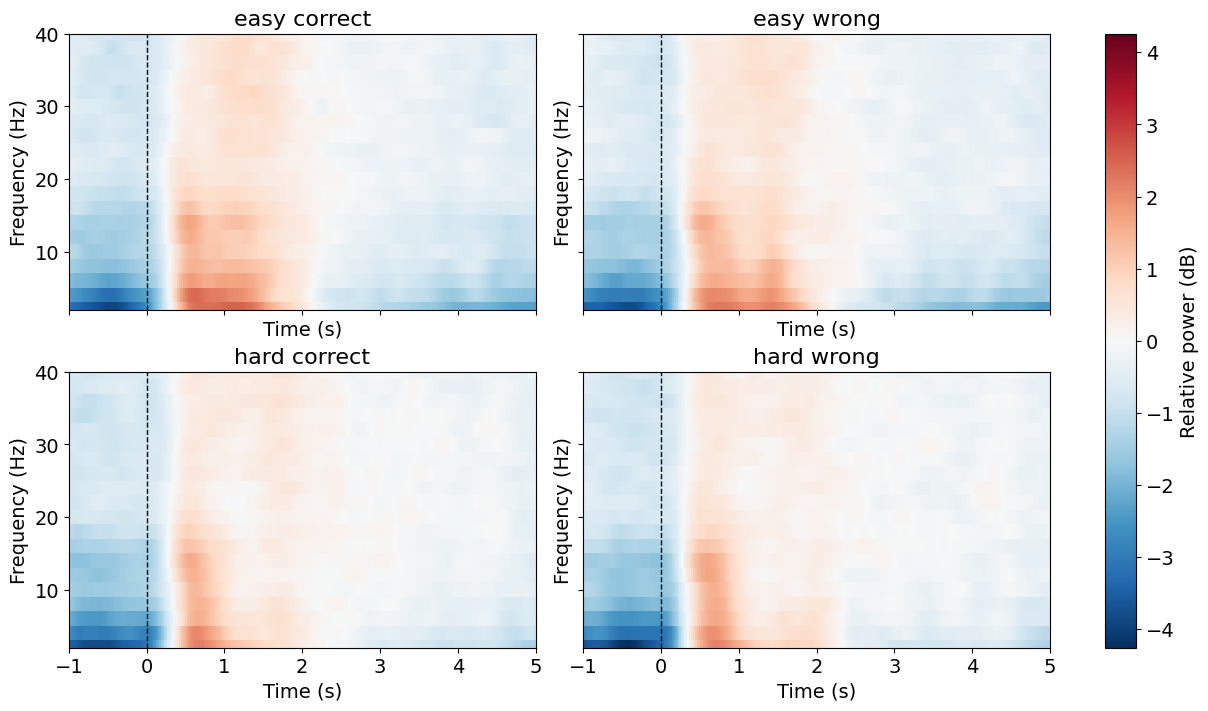

In [6]:
def plot_power_maps(maps, titles):
    rows = len(titles) // 2
    plt.rcParams.update({    
    'font.size': 14,
    'axes.titlesize': 16,
    'svg.fonttype': 'none'})
    fig, axes = plt.subplots(rows, 2, figsize=(12, 3.5 * rows),
                             layout='constrained', sharex=True, sharey=True)
    limit = max(0.1, max((float(np.max(np.abs(power))) for power in maps.values()),
                         default=0.0))
    image = None
    for ax, (marker, title) in zip(axes.flat, titles.items()):
        if marker in maps:
            image = ax.pcolormesh(
                tfr_times, frequencies, maps[marker], shading='nearest',
                cmap='RdBu_r', vmin=-limit, vmax=limit,
            )
        else:
            ax.text(0.5, 0.5, 'No retained epochs', transform=ax.transAxes, ha='center')
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set(title=title, xlim=(TMIN, TMAX), ylim=(2, 40),
               xlabel='Time (s)', ylabel='Frequency (Hz)')
        ax.set_xticks(np.arange(-1, 6))
    if image is not None:
        fig.colorbar(image, ax=axes, label='Relative power (dB)')
    return fig


maps = {marker: np.mean(list(by_recording.values()), axis=0)
        for marker, by_recording in tfr_db_by_recording.items() if by_recording}
if not maps:
    raise ValueError('No retained epochs are available for time-frequency plots')
titles = {marker: marker.replace('_', ' ') for marker in EVENT_ID}
fig = plot_power_maps(maps, titles)
plt.show()


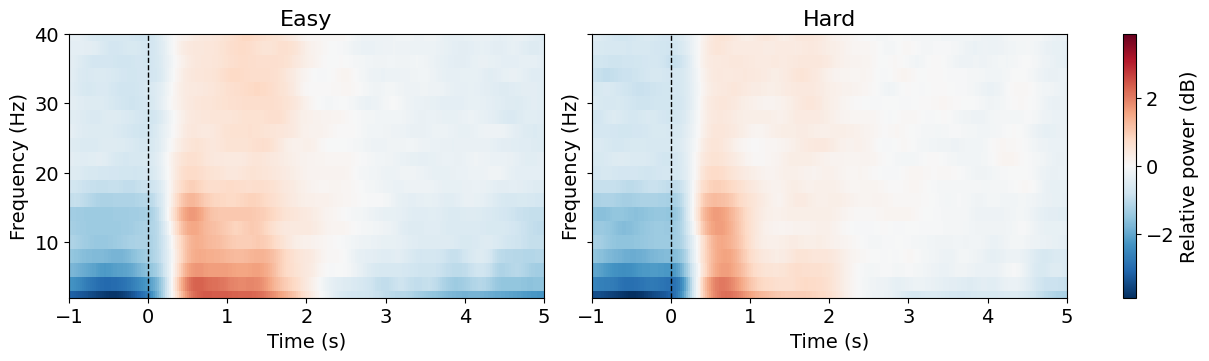

In [7]:
maps, titles = {}, {}
baseline_times = (tfr_times >= TMIN) & (tfr_times <= TMAX)

for difficulty in ('easy', 'hard'):
    recording_maps = []
    n_epochs = 0

    for recording in summary['Recording']:
        markers = [
            f'{difficulty}_{outcome}' for outcome in ('correct', 'wrong')
            if recording in power_by_recording[f'{difficulty}_{outcome}']
        ]
        if not markers:
            continue

        counts = [epoch_counts_by_recording[m][recording] for m in markers]
        mean_power = np.average(
            [power_by_recording[m][recording] for m in markers],
            axis=0, weights=counts,
        )
        baseline = mean_power[:, baseline_times].mean(axis=1, keepdims=True)
        recording_maps.append(10 * np.log10(mean_power / baseline))
        n_epochs += sum(counts)

    if recording_maps:
        maps[difficulty] = np.mean(recording_maps, axis=0)

titles['easy'] = 'Easy'
titles['hard'] = 'Hard'

fig = plot_power_maps(maps, titles)
plt.show()

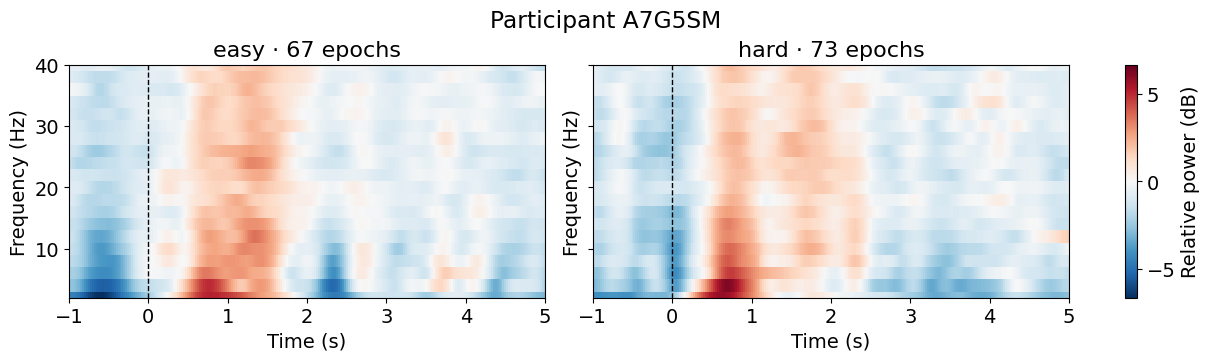

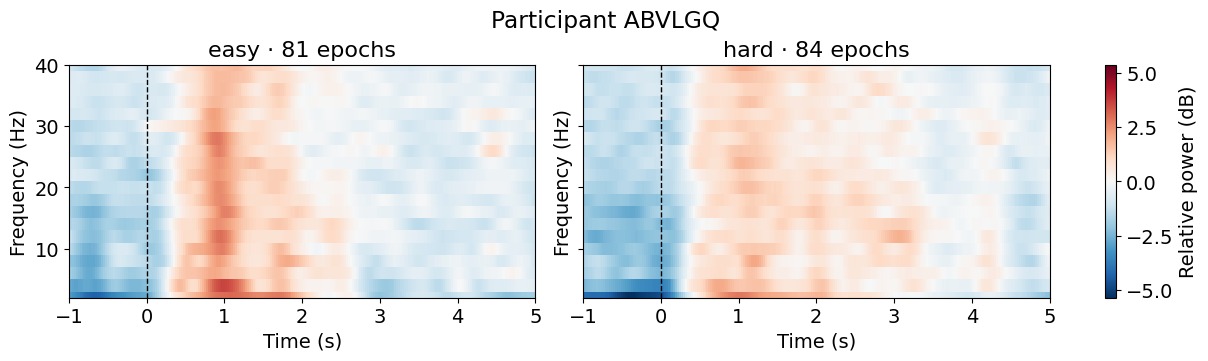

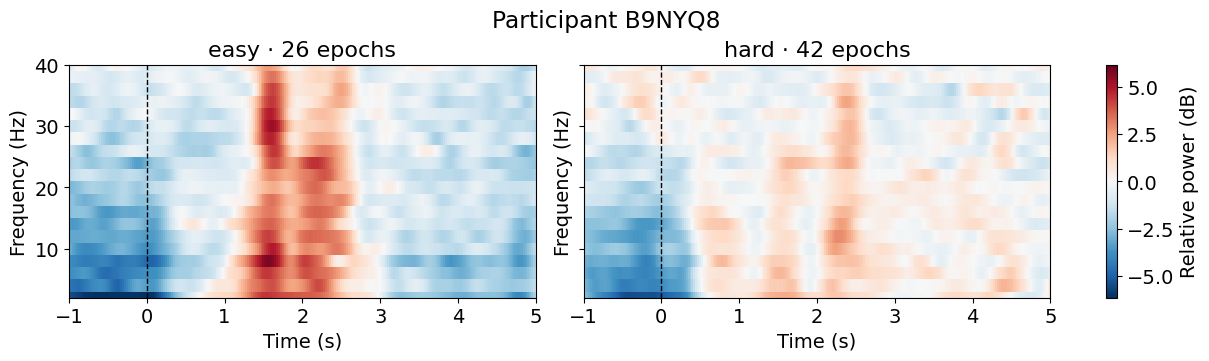

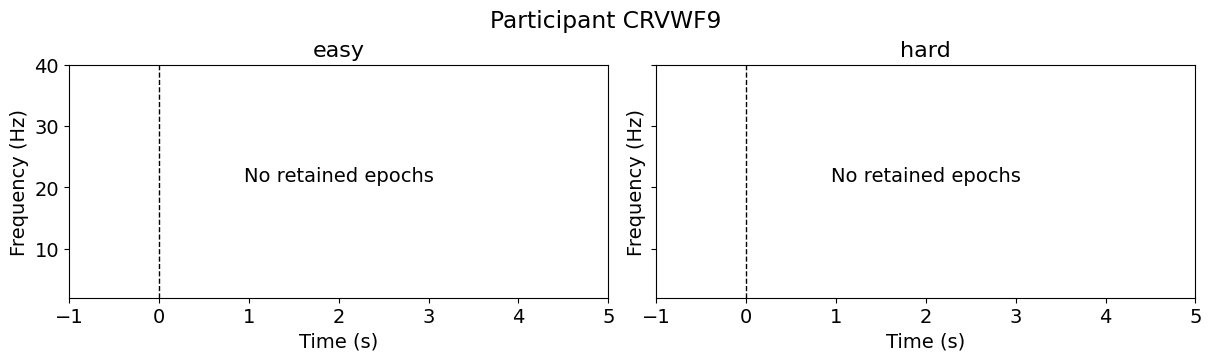

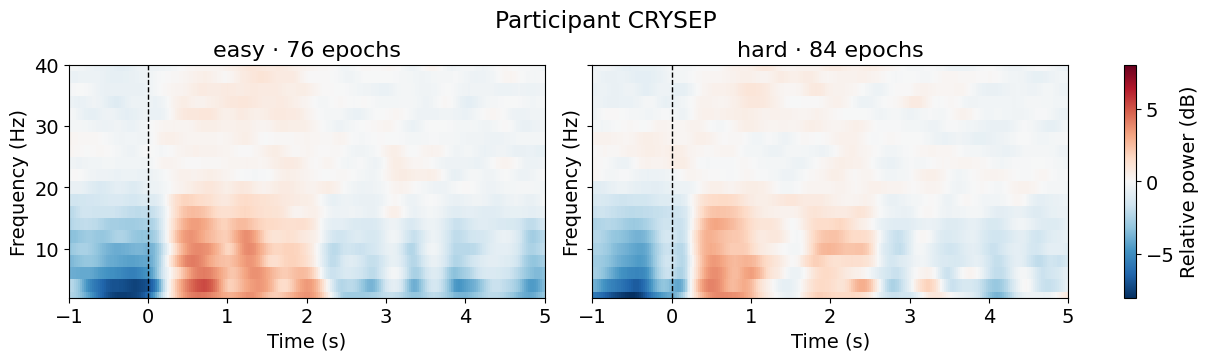

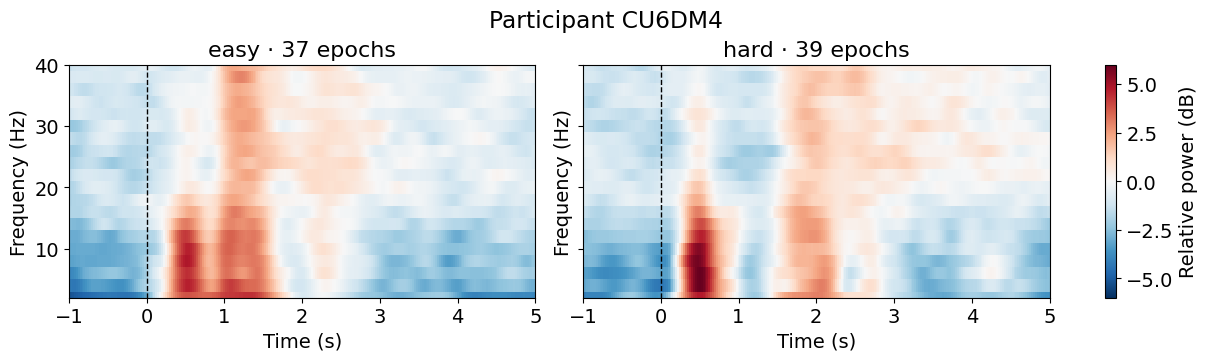

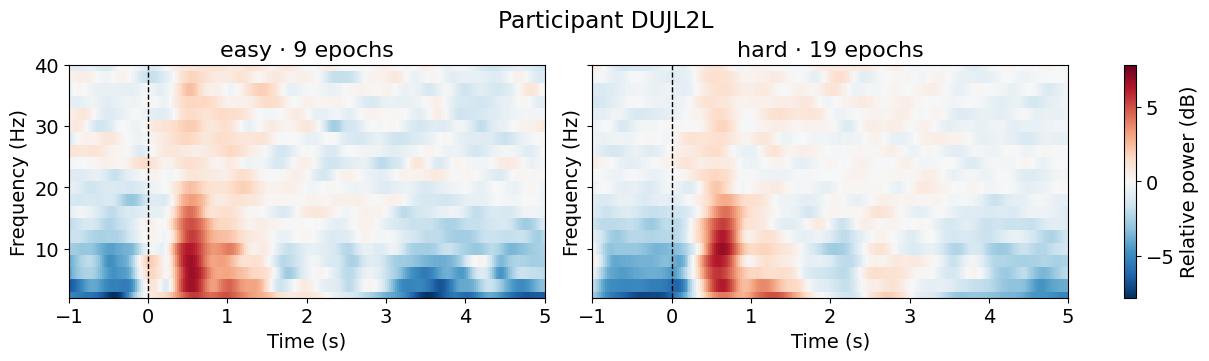

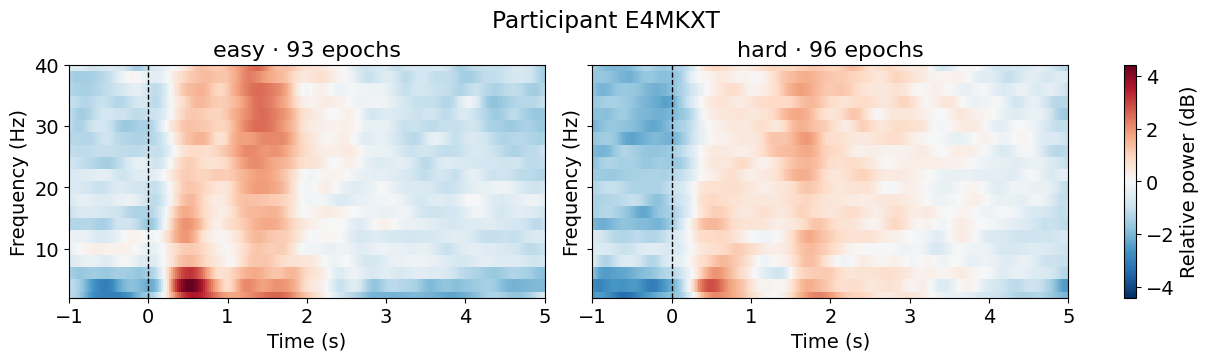

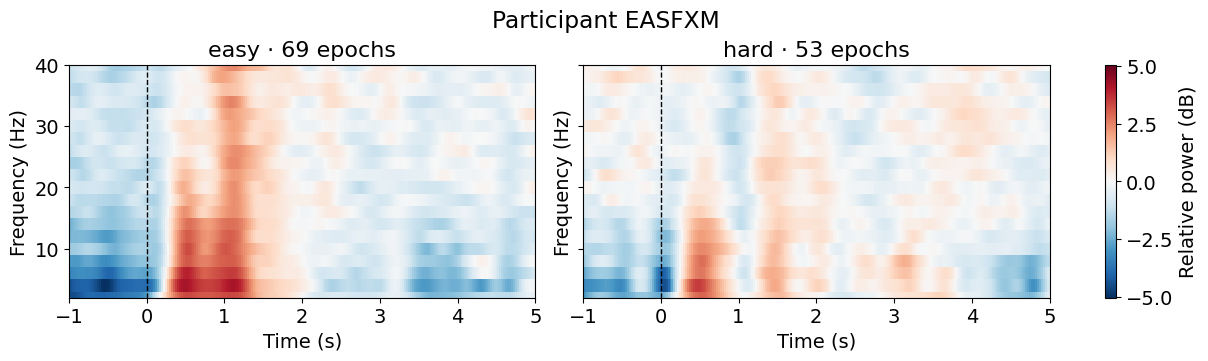

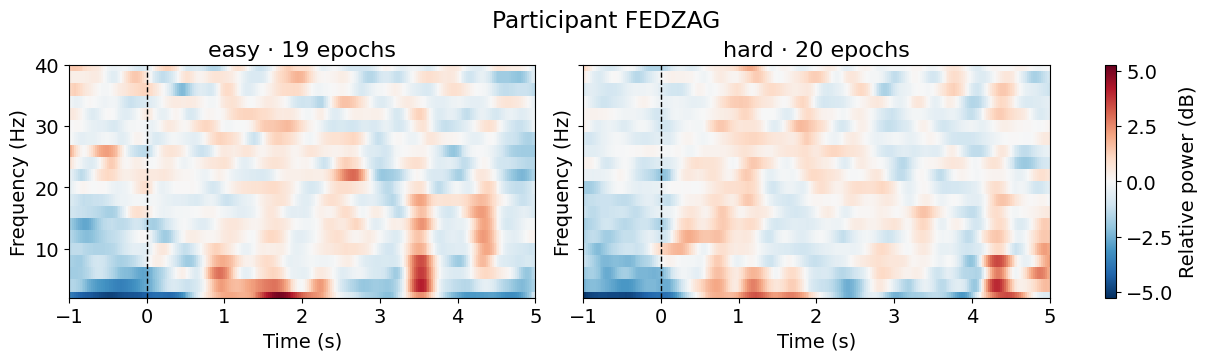

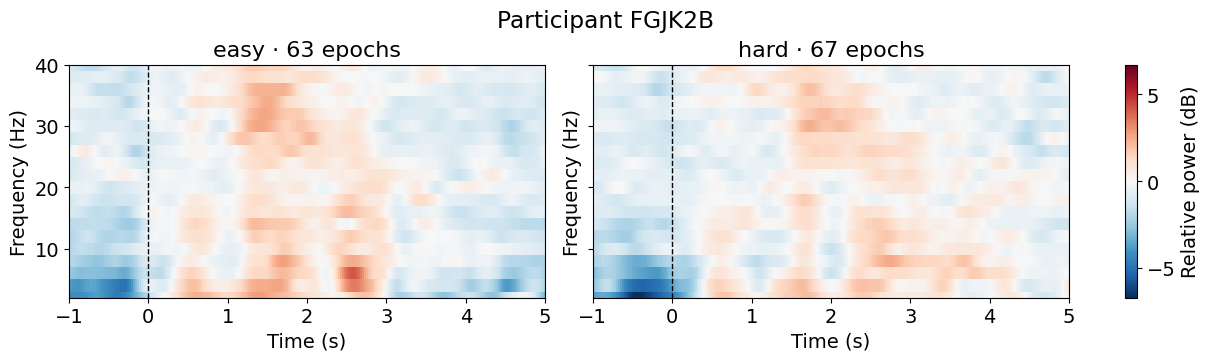

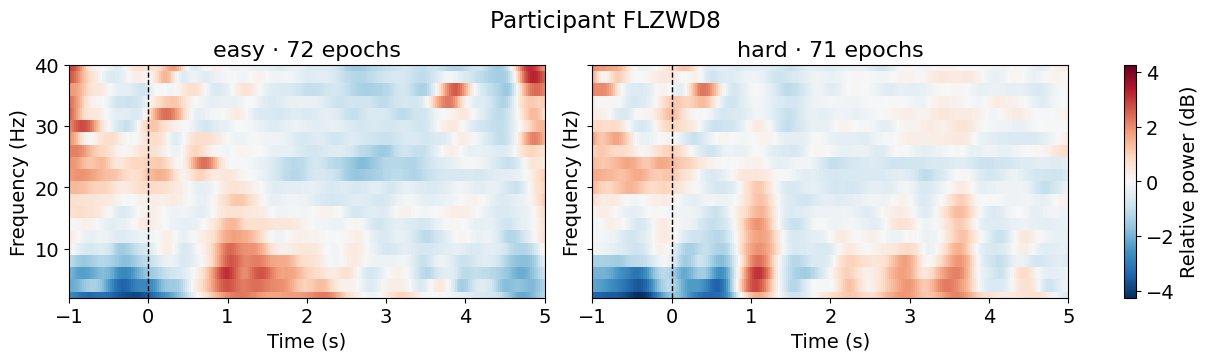

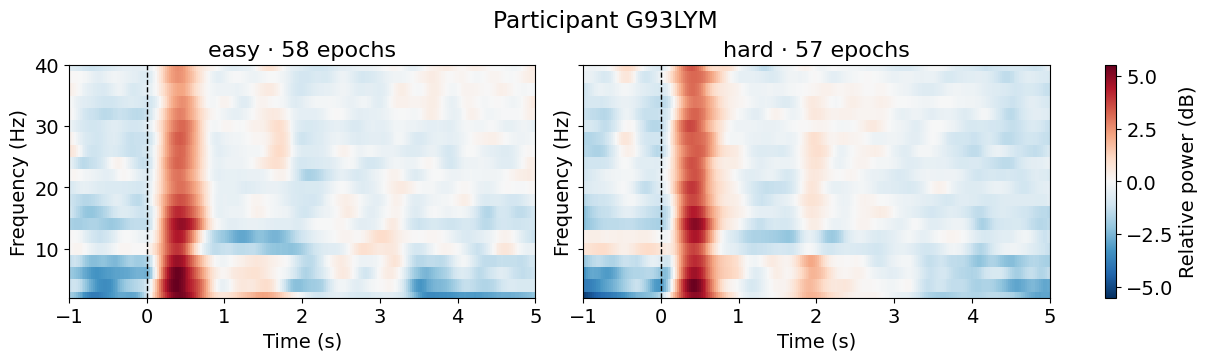

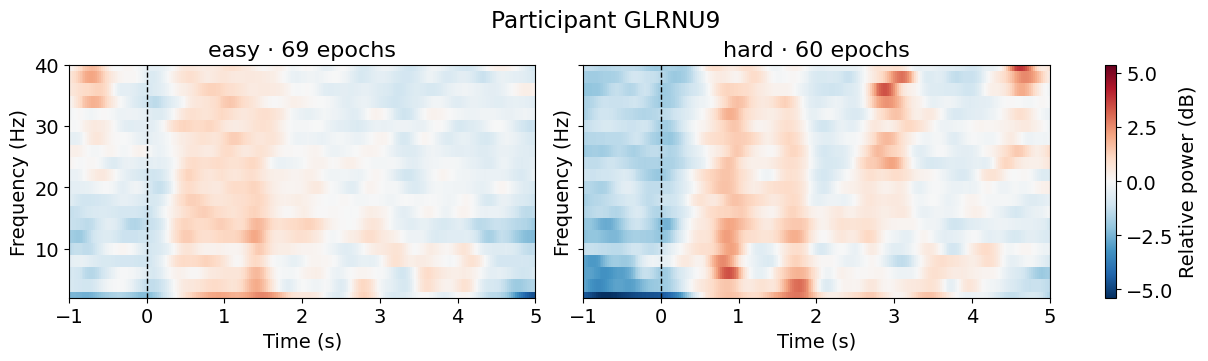

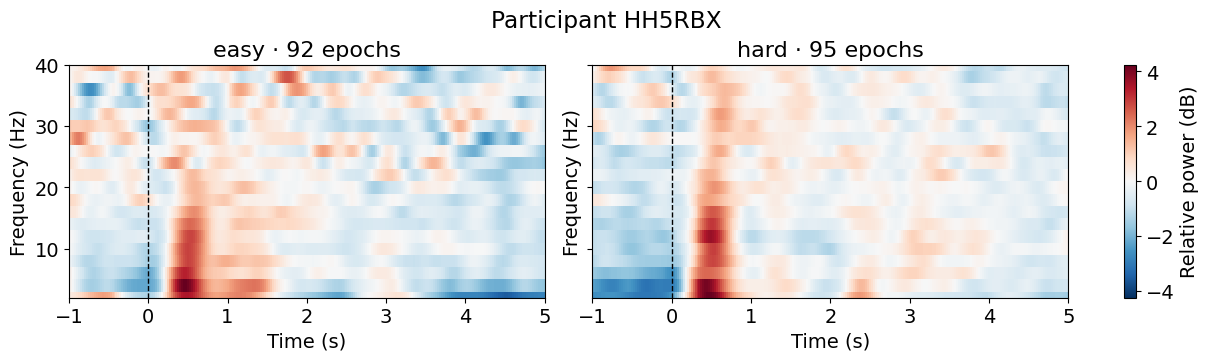

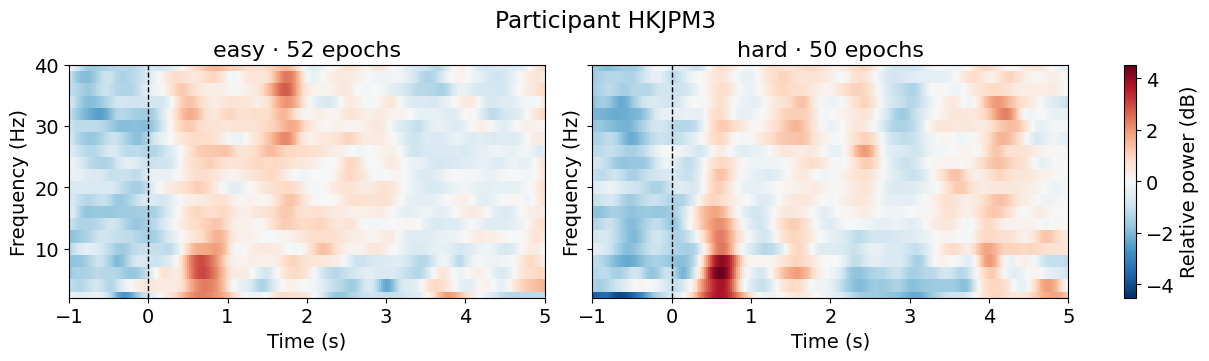

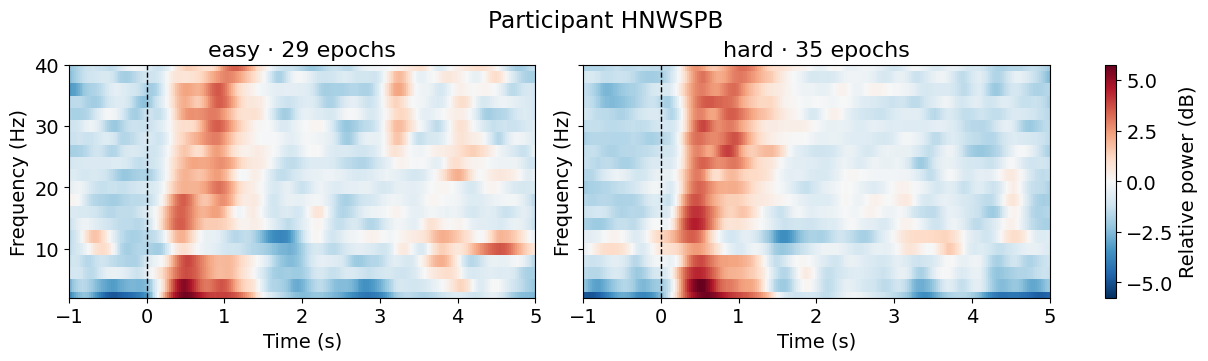

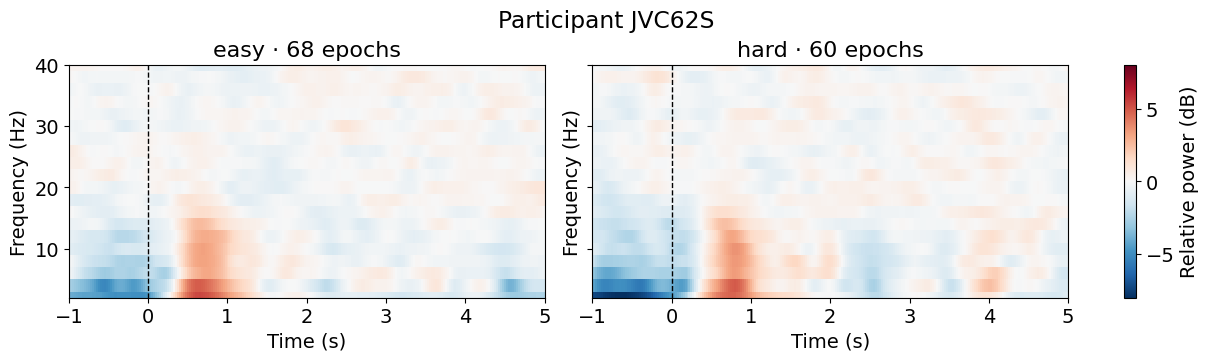

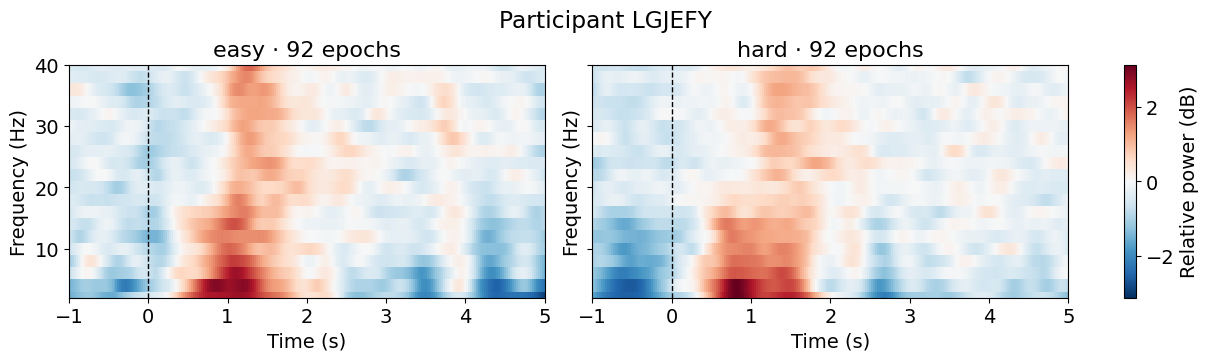

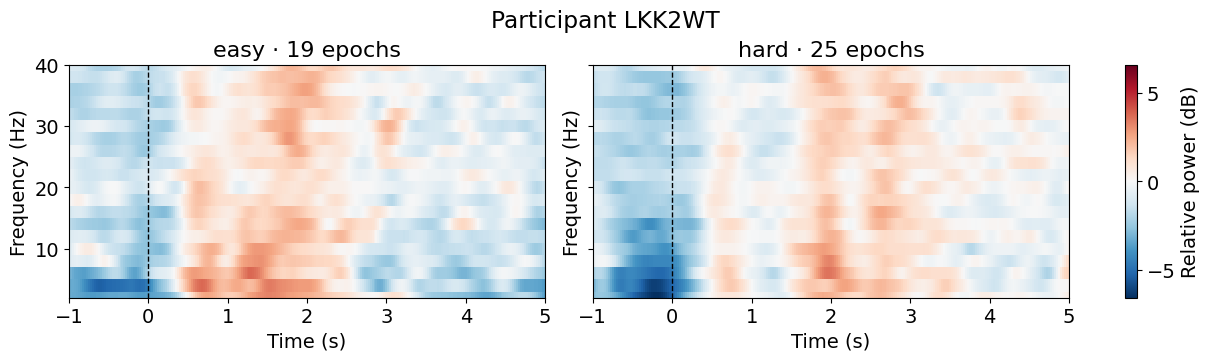

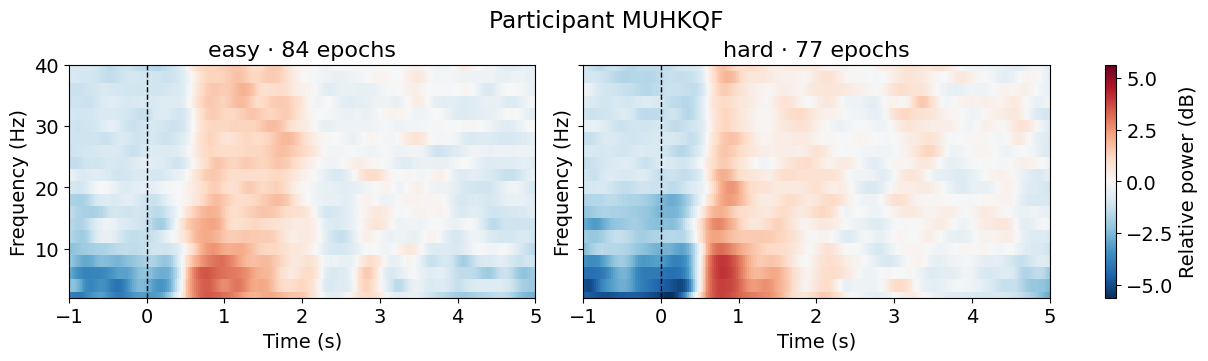

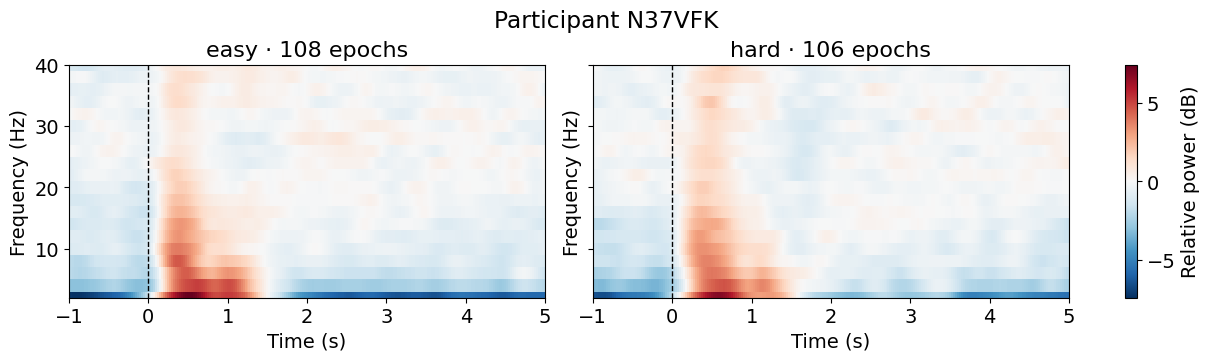

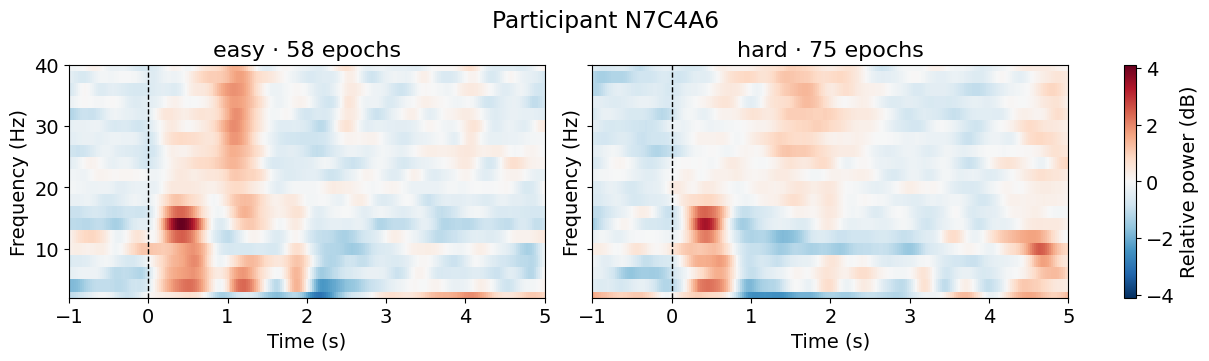

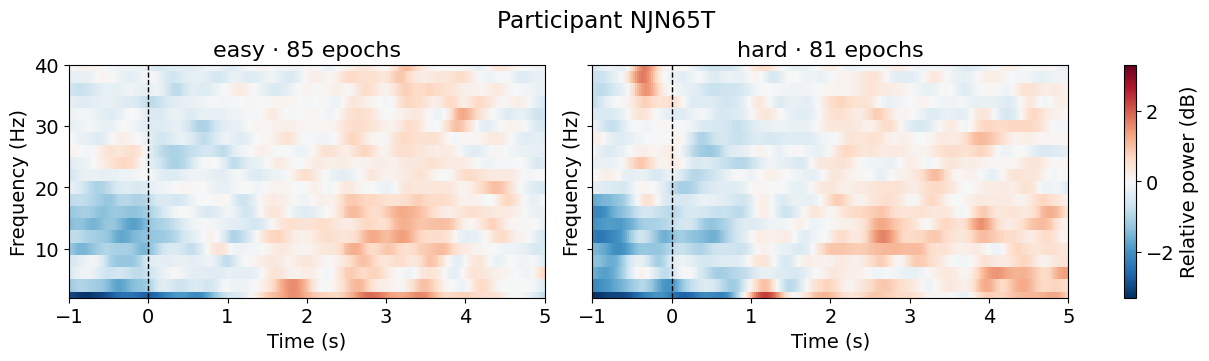

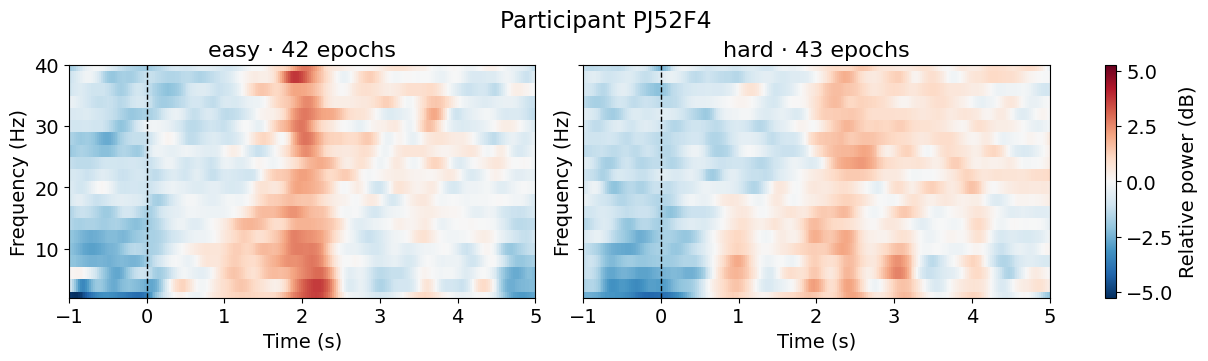

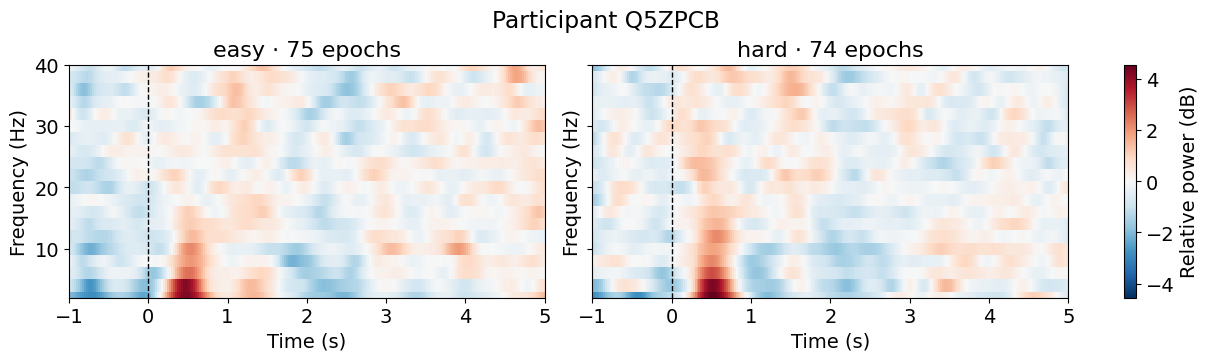

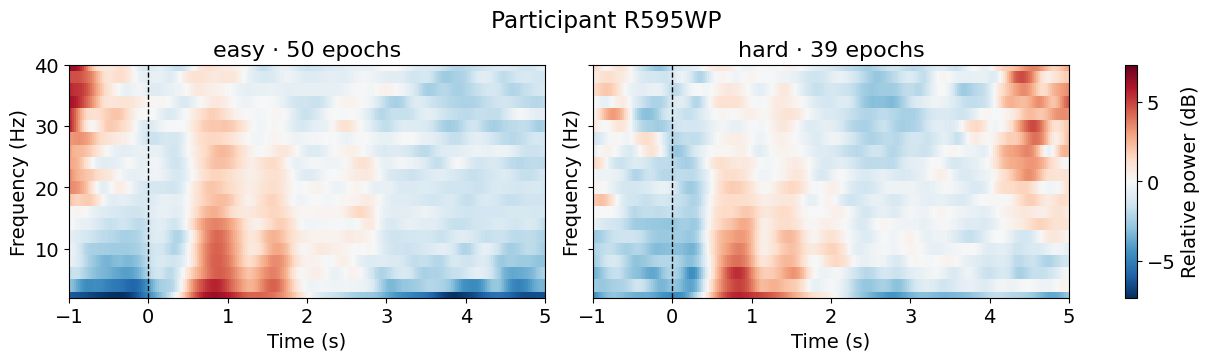

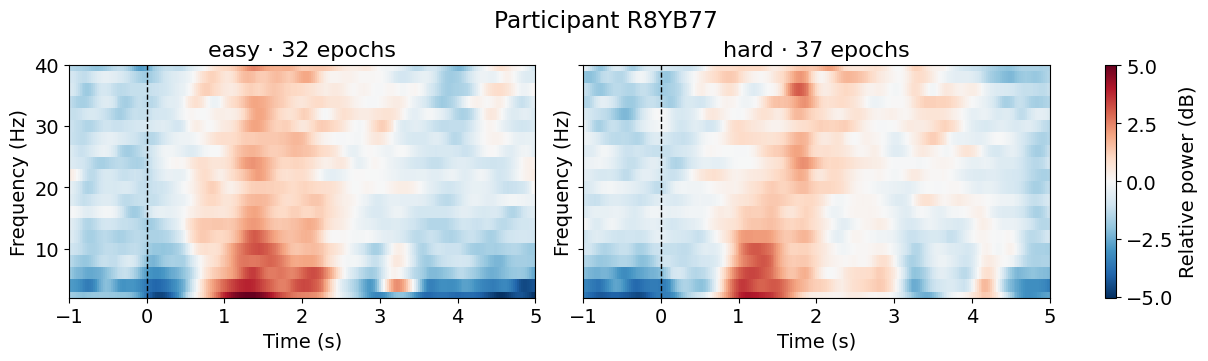

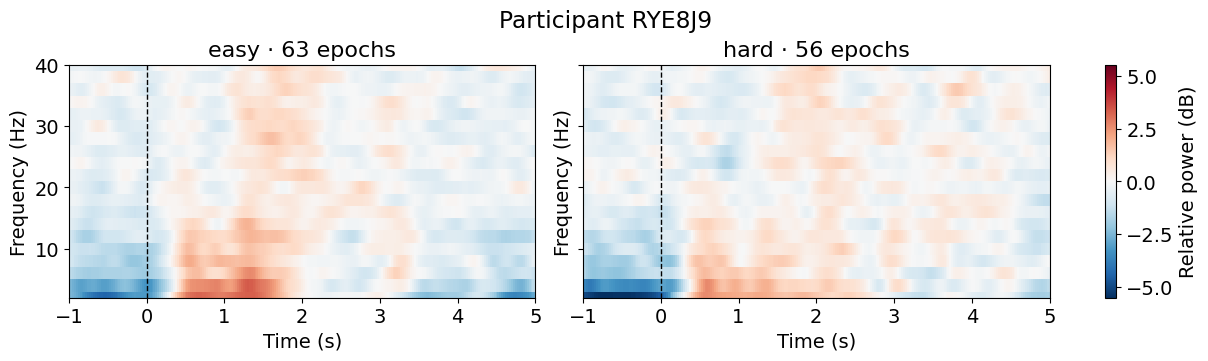

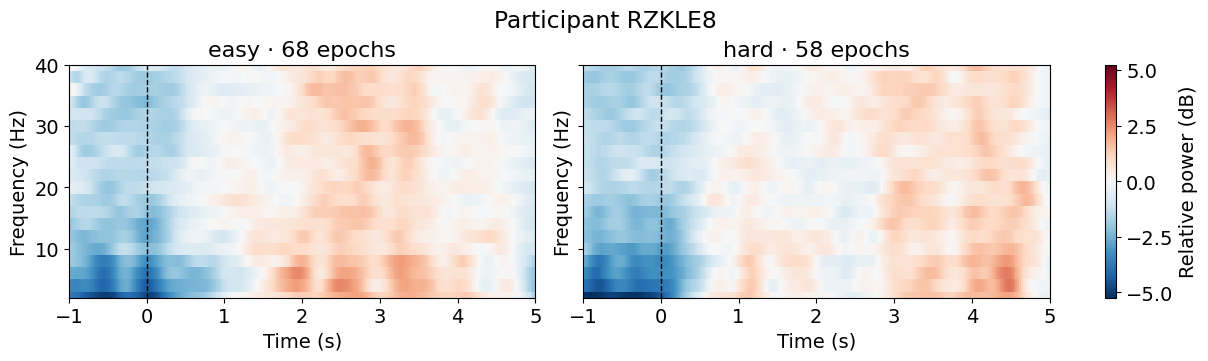

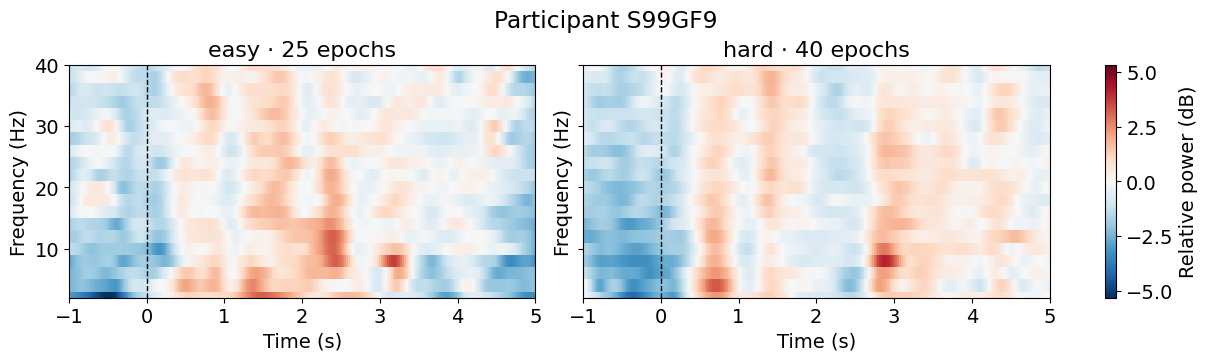

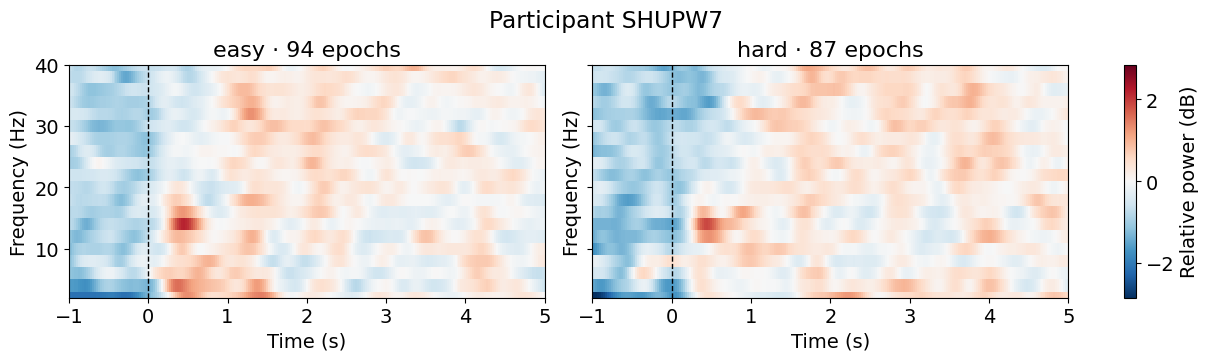

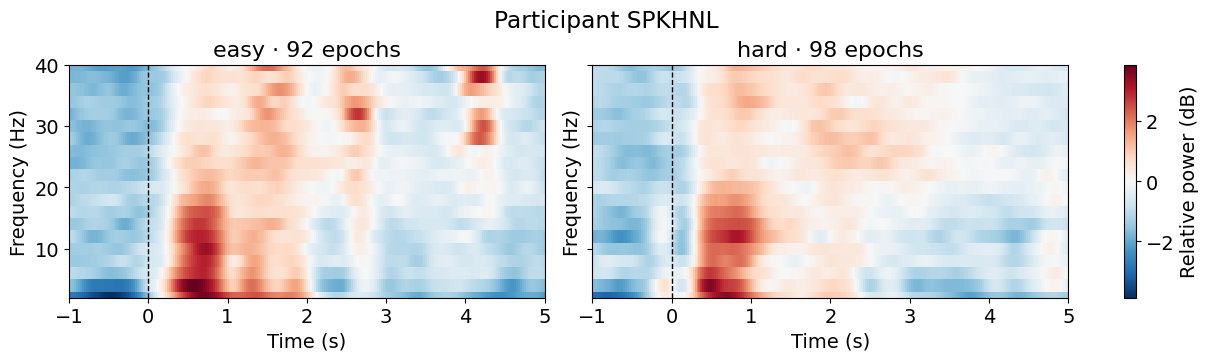

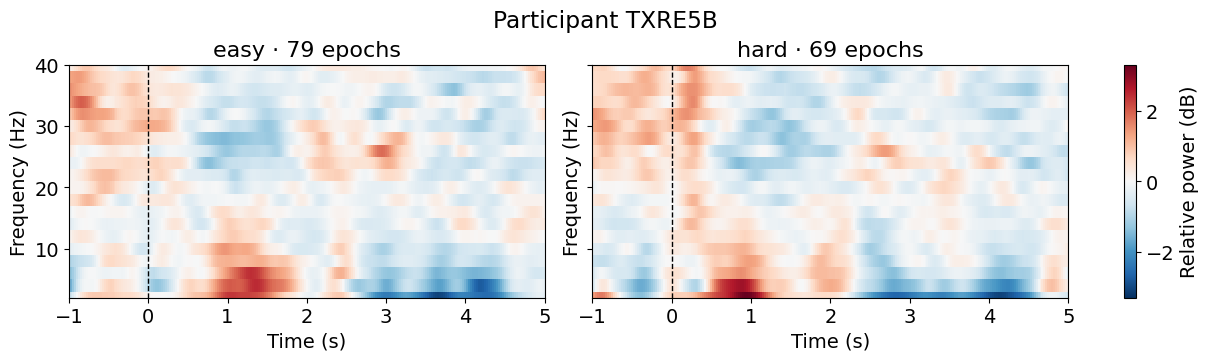

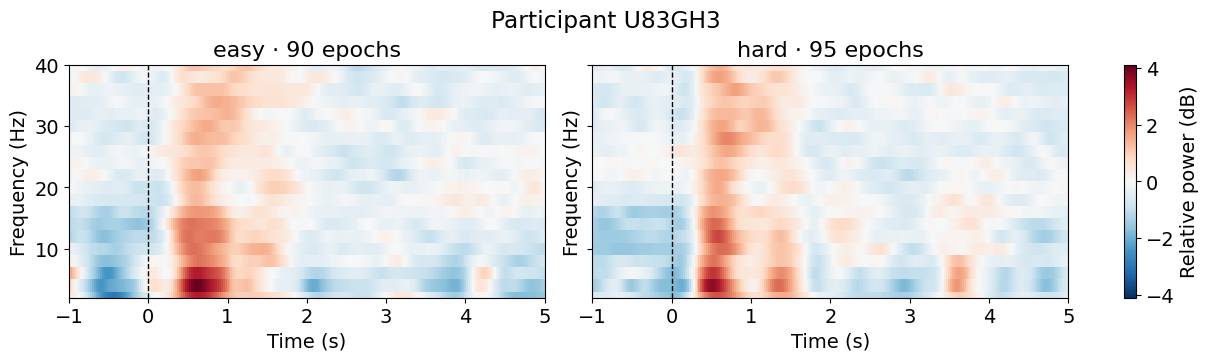

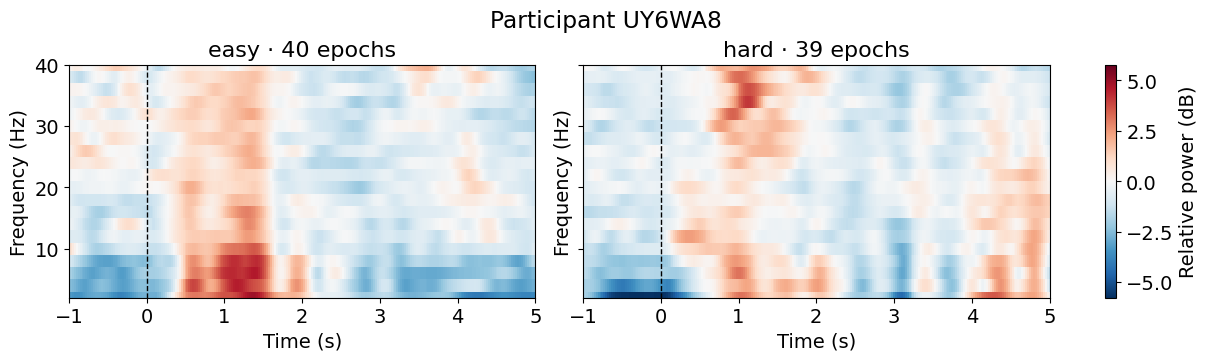

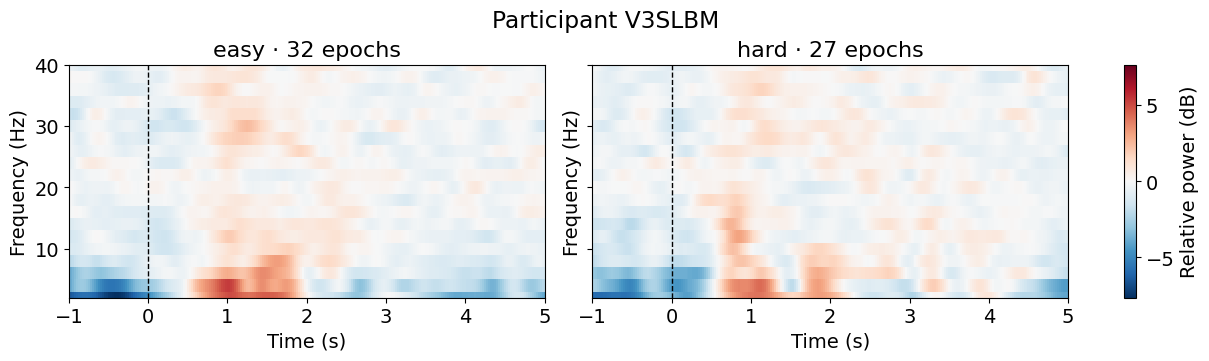

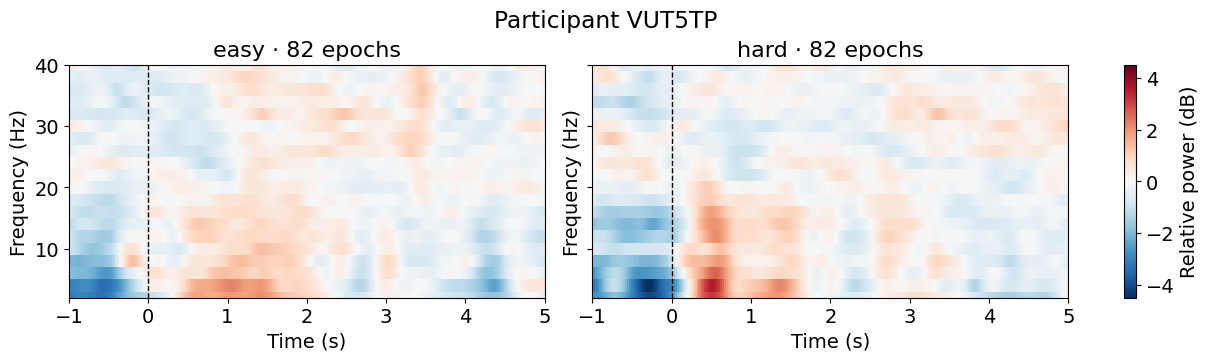

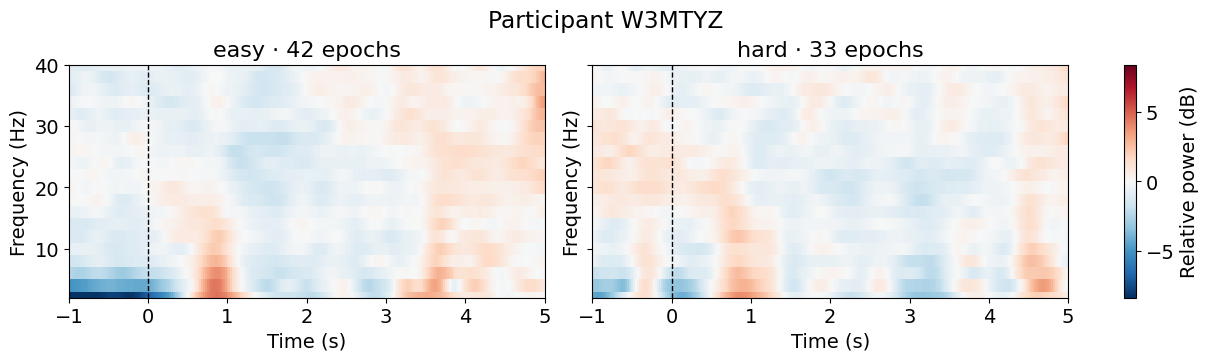

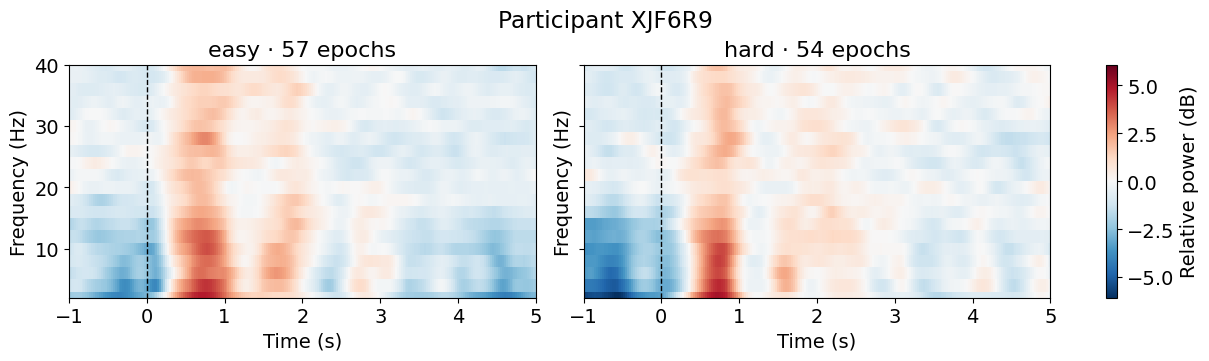

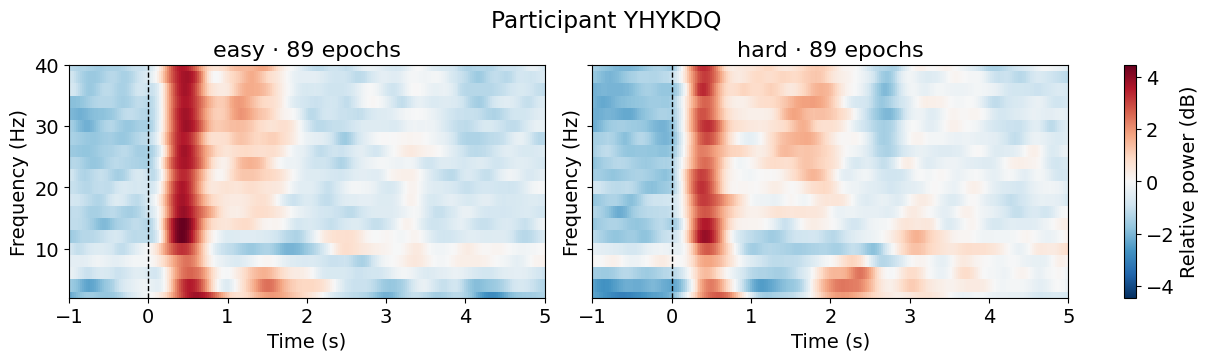

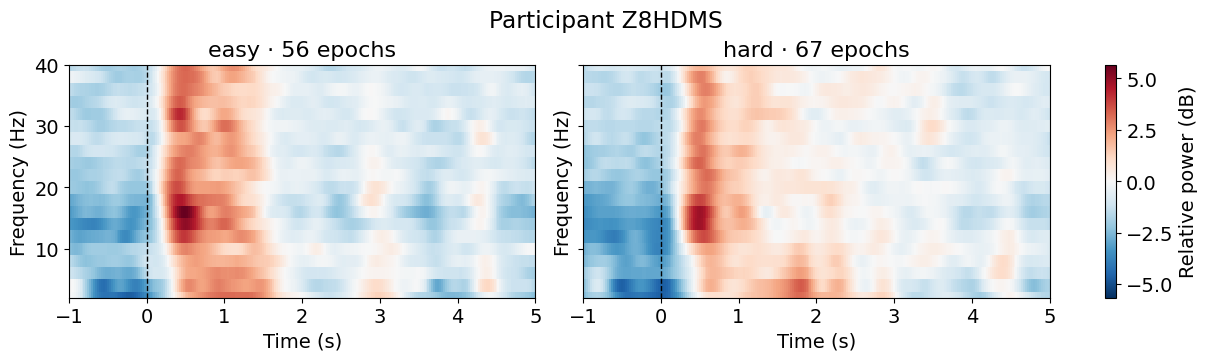

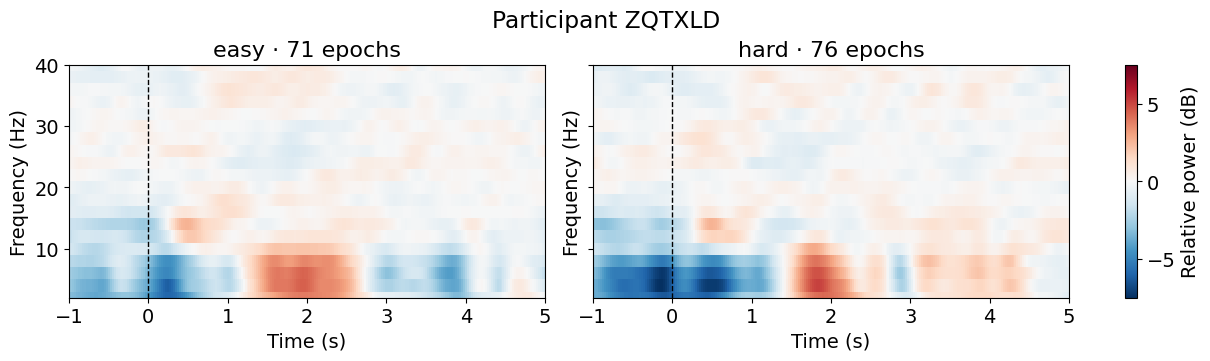

In [8]:
# Pool correct/wrong linear power by retained epoch count, then normalize to baseline.
for recording in summary['Recording']:
    participant = recording.removesuffix('_synchronized').rsplit('_', 1)[0]
    participant_maps, participant_counts = {}, {}
    for difficulty in ('easy', 'hard'):
        markers = [f'{difficulty}_{outcome}' for outcome in ('correct', 'wrong')
                   if recording in power_by_recording[f'{difficulty}_{outcome}']]
        if not markers:
            continue
        counts = [epoch_counts_by_recording[marker][recording] for marker in markers]
        mean_power = np.average(
            [power_by_recording[marker][recording] for marker in markers],
            axis=0, weights=counts,
        )
        baseline_times = (tfr_times >= TMIN) & (tfr_times <= TMAX)
        baseline = mean_power[:, baseline_times].mean(axis=1, keepdims=True)
        participant_maps[difficulty] = 10 * np.log10(mean_power / baseline)
        participant_counts[difficulty] = sum(counts)

    titles = {difficulty: difficulty for difficulty in ('easy', 'hard')}
    for difficulty, count in participant_counts.items():
        titles[difficulty] += f' · {count} epochs'
    fig = plot_power_maps(participant_maps, titles)
    fig.suptitle(f'Participant {participant}')
    plt.show()
    plt.close(fig)
